# 02: Separating Driver from Car

Notebook 01 decided what to measure: each driver's best Q1 lap, as a percentage gap to the fastest
lap of that session. This notebook splits that gap into a driver part and a car part.

### Why this is hard

A lap time depends on the driver and the car together, and you never see one without the other. If
Verstappen is fast in a Red Bull, how much of that is Verstappen?

The answer comes from **drivers changing teams**. When a driver moves, his pace relative to the field
either travels with him or stays behind with the car. Those moves link every driver and every car
into one comparison, and a **hierarchical model** uses all the links at once instead of judging each
driver on his own results.

It is fitted the Bayesian way for two reasons. One driver has a single session and another 154, so
each estimate needs a range rather than a single number. And thin records get pulled toward the field
average instead of being taken at face value.

## Setup and data

`q1_pace.csv` is the output of notebook 01, uploaded here as a Kaggle dataset: one row per driver per
qualifying session, with that driver's percentage gap to the fastest Q1 lap. Bambi lets the model be
written as a single line of text, and PyMC does the computation underneath.

In [1]:
!pip install -q bambi arviz

import pandas as pd
import numpy as np
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
print('bambi', bmb.__version__, '| arviz', az.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.7/107.7 kB 1.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.3/252.3 kB 3.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.5/608.5 kB 8.8 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.9/191.9 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 62.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.4/259.4 kB 21.7 MB/s eta 0:00:00
bambi 0.20.0 | arviz 1.3.0


In [2]:
import glob

# name the file: a bare *.csv glob picks up whichever dataset happens to sort first,
# which silently loaded this notebook's own output on an earlier run
csv_path = glob.glob('/kaggle/input/**/q1_pace.csv', recursive=True)[0]
print('loading:', csv_path)

pace = pd.read_csv(csv_path)
print(pace.shape)
pace.head()

loading: /kaggle/input/datasets/mikandr/q1-pace/q1_pace.csv
(3029, 9)


,season,gp,team,drv,best_lap,n_valid_laps,gap_to_fastest,rain_fraction,within_107
0,2018,Abu Dhabi Grand Prix,Ferrari,RAI,97.010,3,0.242831,0.0,True
1,2018,Abu Dhabi Grand Prix,Ferrari,VET,96.775,3,0.000000,0.0,True
2,2018,Abu Dhabi Grand Prix,Haas F1 Team,GRO,97.575,1,0.826660,0.0,True
3,2018,Abu Dhabi Grand Prix,Haas F1 Team,MAG,97.934,2,1.197623,0.0,True
4,2018,Abu Dhabi Grand Prix,McLaren,ALO,97.890,3,1.152157,0.0,True


## What the data can and cannot answer

Three questions before fitting anything.

How many sessions has each driver been seen in? How many different drivers has each constructor
fielded? And how many drivers have driven for more than one team, since those moves are what make it
possible to tell driver apart from car.

In [3]:
model_data = pace[pace['within_107']].copy()
print('rows:', len(model_data), 'of', len(pace), '(107% rule applied)')
print('drivers:', model_data['drv'].nunique(),
      '| constructors:', model_data['team'].nunique(),
      '| seasons:', model_data['season'].nunique())
print()
print('sessions per driver:')
print(model_data['drv'].value_counts().describe().round(1))

rows: 3008 of 3029 (107% rule applied)
drivers: 43 | constructors: 19 | seasons: 8

sessions per driver:
count     43.0
mean      70.0
std       53.7
min        1.0
25%       22.0
50%       59.0
75%      122.5
max      154.0
Name: count, dtype: float64


In [4]:
teams_per_driver = model_data.groupby('drv')['team'].nunique()
print('constructors driven for, per driver:')
print(teams_per_driver.value_counts().sort_index().rename('n_drivers'))
print()
print(f'drivers who switched constructor: {(teams_per_driver > 1).sum()} of {len(teams_per_driver)}')

constructors driven for, per driver:
team
1    20
2    11
3     6
4     3
5     3
Name: n_drivers, dtype: int64

drivers who switched constructor: 23 of 43


### What this tells me

**Some drivers have been seen far more often than others.** Sessions per driver run from **1 to
154**, median 59. A simple per-driver average would treat the driver with one session as seriously as
the driver with 154.

**23 of 43 drivers switched team**, by the names as recorded. Notebook 01 explains why moves matter
and why they are not the only thing that helps: a driver who stays put is still measured against a
run of teammates who drove elsewhere.

## Checking the model's starting assumptions

### Reading the model formula

The model is one line:

```
gap_to_fastest ~ 1 + (1|drv) + (1|team) + (1|season)
```

A driver's percentage gap is an overall average across the whole dataset (`1`), plus an adjustment
for who was driving, plus one for whose car he was in, plus one for the season.

The `(1|x)` notation is what makes the model **hierarchical**. Without it the model would fit 43
unrelated driver numbers. With it, the 43 adjustments are treated as coming from one shared distribution, and the
model estimates how wide that distribution is: how far apart are drivers, typically? One number
answers that for drivers, another for cars, and comparing the two is the point of the project.

### What the model believes before it sees any lap times

Every Bayesian model needs a starting assumption about which values are plausible, called a
**prior**. Bambi picks priors automatically and its defaults know nothing about Formula 1.

The check is to ignore the data, draw gaps from the priors alone, and see what the model treats as
normal. Notebook 01 measured real gaps at 0% to 7%. If the priors happily produce a gap of 50%, the
model starts from an unreasonable place, and it is cheaper to catch that now than to diagnose it
later.

### A quick check before fitting anything

This section is hygiene rather than a finding: it takes two cells, and the model would have reached
much the same answer without it.

Bambi scales its default priors from the data, so they are loose but not detached from reality. What
nothing tells it is that this quantity has a floor at zero, since nothing can be faster than the
fastest lap of the session.

In [5]:
formula = 'gap_to_fastest ~ 1 + (1|drv) + (1|team) + (1|season)'
model = bmb.Model(formula, data=model_data)
model.build()

prior_check = model.prior_predictive(draws=500, random_seed=0)
simulated = prior_check.prior_predictive['gap_to_fastest'].values.flatten()
observed = model_data['gap_to_fastest'].values

print('prior predictive (before seeing data):')
print(f'  range          : {simulated.min():.1f}% to {simulated.max():.1f}%')
print(f'  negative gaps  : {(simulated < 0).mean():.1%}  (impossible)')
print(f'  above 7%       : {(simulated > 7).mean():.1%}  (would fail the 107% rule)')
print()
print('observed data:')
print(f'  range          : {observed.min():.2f}% to {observed.max():.2f}%')

Sampling: [1|drv_offset, 1|drv_sigma, 1|season_offset, 1|season_sigma, 1|team_offset, 1|team_sigma, Intercept, gap_to_fastest, sigma]


prior predictive (before seeing data):
  range          : -32.1% to 34.5%
  negative gaps  : 40.5%  (impossible)
  above 7%       : 7.2%  (would fail the 107% rule)

observed data:
  range          : 0.00% to 6.91%


### The defaults are too loose

**40.5% of the gaps drawn from the default priors are negative**, spanning −32% to +34.5% where
reality spans 0% to 6.9%. Before seeing a lap time, the model treats a driver going 30% faster than
the session's fastest lap as unremarkable.

With 3,008 driver-sessions the data would pull it back, so this would not have been fatal. But
notebook 01 already measured what sensible looks like, so there is no reason to start somewhere
absurd:

- **Intercept ~ Normal(1, 0.5)**: the average driver is about 1% off the fastest lap.
- **Group SDs ~ HalfNormal(0.5)**: differences between drivers, and between cars, must be smaller
  than the total spread of 0.83%.
- **sigma ~ HalfNormal(1)**: session-to-session noise of roughly the size seen in the data.

These keep the model inside physically possible values without dictating the answer.

In [6]:
priors = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|team': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    'sigma': bmb.Prior('HalfNormal', sigma=1),
}

model = bmb.Model(formula, data=model_data, priors=priors)
model.build()

prior_check = model.prior_predictive(draws=500, random_seed=0)
simulated = prior_check.prior_predictive['gap_to_fastest'].values.flatten()

print('prior predictive, tightened:')
print(f'  range          : {simulated.min():.1f}% to {simulated.max():.1f}%')
print(f'  negative gaps  : {(simulated < 0).mean():.1%}')
print(f'  above 7%       : {(simulated > 7).mean():.1%}')

Sampling: [1|drv_offset, 1|drv_sigma, 1|season_offset, 1|season_sigma, 1|team_offset, 1|team_sigma, Intercept, gap_to_fastest, sigma]


prior predictive, tightened:
  range          : -10.7% to 12.6%
  negative gaps  : 21.3%
  above 7%       : 0.1%


**Better, though not perfect.** Negative gaps fall from 40.5% to 21.3%, and gaps beyond the 107%
threshold nearly vanish (7.2% → 0.1%). What remains comes from using a symmetric bell curve at all,
and is dealt with later by changing the distribution rather than the priors.

## Fitting the first model

**Start with the simplest version that could work**: an ordinary bell curve on the gap exactly as
measured. It is also the most readable, since a driver effect comes out directly as "this many
percent of lap time", so it is the right baseline for anything else to beat.

Fitting is done by MCMC, which samples the space of possible answers in proportion to how well each one explains
the data. The result is not one number per driver but thousands of plausible ones, and their spread
*is* the uncertainty. Four independent runs, called chains, start in different places; if they agree
at the end, that is evidence the procedure worked.

In [7]:
idata = model.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                  idata_kwargs={'log_likelihood': True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_sigma, 1|team_offset, 1|season_sigma, 1|season_offset]


Output()

/usr/local/lib/python3.12/dist-packages/pymc/sampling/mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 29 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


## Checking that the fitting procedure worked

**Did the procedure explore the model properly?** Three checks, before any result is read.

The sampler reported **2 divergences out of 8,000 samples**. A divergence means it hit a region it
could not step through accurately, usually where one group's spread approaches zero and the space
narrows. That rate is low but not zero, so it is worth reading alongside the other two checks.

**R-hat** compares how much each chain moved on its own against how much the four differ from each
other: 1.00 means they agree, above about 1.01 they do not. **ESS** counts how many independent
samples the run is worth, since consecutive MCMC samples resemble one another. Hundreds per estimate
is fine.

In [8]:
summary = az.summary(idata)

print('worst R-hat      :', summary['r_hat'].max())
print('lowest ESS bulk  :', int(summary['ess_bulk'].min()))
print('lowest ESS tail  :', int(summary['ess_tail'].min()))
print('divergences      :', int(idata.sample_stats['diverging'].sum()))
print()
print('parameters with R-hat > 1.01:', (summary['r_hat'] > 1.01).sum())
print('parameters with ESS < 400   :', (summary['ess_bulk'] < 400).sum())
print()
summary.loc[['Intercept', 'sigma', '1|drv_sigma', '1|team_sigma', '1|season_sigma']]

worst R-hat      : 1.0020216061994875
lowest ESS bulk  : 2522
lowest ESS tail  : 3457
divergences      : 2

parameters with R-hat > 1.01: 0
parameters with ESS < 400   : 0



,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,1.308,0.132,1.1,1.5,2522,3457,1.00,0.0026,0.0019
sigma,0.6416,0.0084,0.63,0.66,9901,5837,1.00,8.5e-05,5.9e-05
1|drv_sigma,0.48,0.061,0.39,0.59,2543,3632,1.00,0.0012,0.00099
1|team_sigma,0.328,0.063,0.24,0.44,3572,4457,1.00,0.0011,0.001
1|season_sigma,0.231,0.077,0.14,0.37,3342,4320,1.00,0.0013,0.0016


### The procedure worked, and the answer is wrong

**All three checks pass.** Every R-hat is 1.00, effective sample sizes are in the thousands, and
there were 2 divergences out of 8,000 samples.

**The answer it arrived at is still not believable:**

| effect | sd (% of lap time) |
|---|---|
| driver | **0.48** |
| constructor | **0.33** |
| season | 0.23 |
| residual | 0.64 |

**Drivers come out more spread apart than cars.** Formula 1 says the opposite. The quickest car on
the grid is routinely 2–3% of lap time ahead of the slowest, while two drivers in the same car are
usually within 0.2–0.3% of each other. A result this far from the sport is a mistake in how the model
was written, not a discovery.

**The mistake is `(1|team)`.** It gives each constructor a single number covering all eight seasons.
But an F1 car is designed and built again every year. Mercedes in 2019 was dominant; the 2022 car
bounced so badly down the straights that the team spent the year fixing it. Averaging those into one
"Mercedes" number throws away the variation this project exists to measure.

### The fix: a car is a team in a given year

Replacing `(1|team)` with `(1|team_season)`, a column that pastes the two together, gives every car
its own number. "Mercedes 2019" and "Mercedes 2022" become two different cars, which is what they
were.

Driver and car can still be told apart, and arguably more cleanly:

- **Teammates share a car for a season.** Two drivers, the same car, different lap times: the
  difference is down to the drivers, with the car held constant.
- **Drivers move between teams across seasons**, which links those separate cars onto one common
  scale.

I keep `(1|season)` as well, to absorb effects that hit the whole grid at once, such as a regulation
change bunching the field together or spreading it out.

In [9]:
model_data['team_season'] = model_data['team'] + ' ' + model_data['season'].astype(str)
print('team-seasons:', model_data['team_season'].nunique())
print('drivers per team-season:')
print(model_data.groupby('team_season')['drv'].nunique().value_counts().sort_index())

team-seasons: 81
drivers per team-season:
drv
2    66
3    14
4     1
Name: count, dtype: int64


In [10]:
formula_v2 = 'gap_to_fastest ~ 1 + (1|drv) + (1|team_season) + (1|season)'

priors_v2 = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=1.0)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    'sigma': bmb.Prior('HalfNormal', sigma=1),
}

model_v2 = bmb.Model(formula_v2, data=model_data, priors=priors_v2)

# log_likelihood is needed for the LOO comparison later, and Bambi's non-centred
# parameterisation means it cannot be recovered after the fact
idata_v2 = model_v2.fit(draws=2000, tune=1000, chains=4, random_seed=0, target_accept=0.95,
    idata_kwargs={'log_likelihood': True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

/usr/local/lib/python3.12/dist-packages/pymc/sampling/mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 57 seconds.


In [11]:
summary_v2 = az.summary(idata_v2)

print('worst R-hat    :', summary_v2['r_hat'].max())
print('lowest ESS bulk:', int(summary_v2['ess_bulk'].min()))
print('divergences    :', int(idata_v2.sample_stats['diverging'].sum()))
print()
summary_v2.loc[['Intercept', 'sigma', '1|drv_sigma', '1|team_season_sigma', '1|season_sigma']]

worst R-hat    : 1.0052625645757556
lowest ESS bulk: 1152
divergences    : 0



,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,1.201,0.1,1,1.4,5359,4493,1.00,0.0014,0.0012
sigma,0.6109,0.0081,0.6,0.62,12215,5852,1.00,7.4e-05,5.4e-05
1|drv_sigma,0.275,0.047,0.21,0.36,3945,5236,1.00,0.00074,0.00058
1|team_season_sigma,0.442,0.044,0.38,0.52,2774,4171,1.00,0.00084,0.00062
1|season_sigma,0.189,0.1,0.045,0.36,1152,1285,1.01,0.0028,0.0027


### Treating each year's car separately fixes it

| effect | `(1\|team)` | `(1\|team_season)` |
|---|---|---|
| driver | 0.48 | **0.275** |
| car | 0.33 | **0.442** |

**Cars now vary more than drivers**, which is what the sport looks like. The driver number also
**fell by 43%**. The first model was crediting drivers with performance that belonged to their cars:
with Mercedes 2019 and Mercedes 2022 forced into one number, the car's year-to-year swings had
nowhere to go except the driver term.

**The divergences went away entirely**, from 2 to none. But three things changed between the two fits
and the credit cannot be split between them here: the formula gained a per-season car term, the car
prior widened, and `target_accept` went from its default of 0.8 to 0.95. That last setting controls
how cautiously the procedure moves: higher values mean smaller steps, which cost time but get through
awkward regions more reliably.

**One weak number to carry forward.** `1|season_sigma`, the spread between seasons, has the worst
diagnostics in the fit (R-hat 1.01, the lowest effective sample size). With only 8 seasons there is
little to go on when estimating how much seasons differ, so that number is poorly pinned down however
the model is fitted. It matters little for the driver-versus-car question, but it should not be
quoted with confidence.

## Does the fitted model produce data that looks like Formula 1?

The convergence checks said the fitting procedure did its job. They said nothing about whether the
model resembles reality. This check simulates a fresh set of qualifying gaps from the fitted model
and compares them against the real ones.

The worry raised earlier comes back here. An ordinary bell curve can produce negative numbers, and
a gap to the fastest lap cannot be negative.

In [12]:
model_v2.predict(idata_v2, kind='response', random_seed=0)
replicated = idata_v2.posterior_predictive['gap_to_fastest'].values.flatten()
observed = model_data['gap_to_fastest'].values

print('posterior predictive vs observed:')
print(f'  negative values : {(replicated < 0).mean():.1%}  (observed: {(observed < 0).mean():.1%})')
print(f'  min             : {replicated.min():.2f}%   (observed: {observed.min():.2f}%)')
print(f'  max             : {replicated.max():.2f}%   (observed: {observed.max():.2f}%)')
print(f'  median          : {np.median(replicated):.2f}%   (observed: {np.median(observed):.2f}%)')
print(f'  skew            : {float(pd.Series(replicated).skew()):.2f}    (observed: {pd.Series(observed).skew():.2f})')

posterior predictive vs observed:
  negative values : 8.6%  (observed: 0.0%)
  min             : -2.77%   (observed: 0.00%)
  max             : 6.10%   (observed: 6.91%)
  median          : 1.06%   (observed: 0.95%)
  skew            : 0.29    (observed: 1.63)


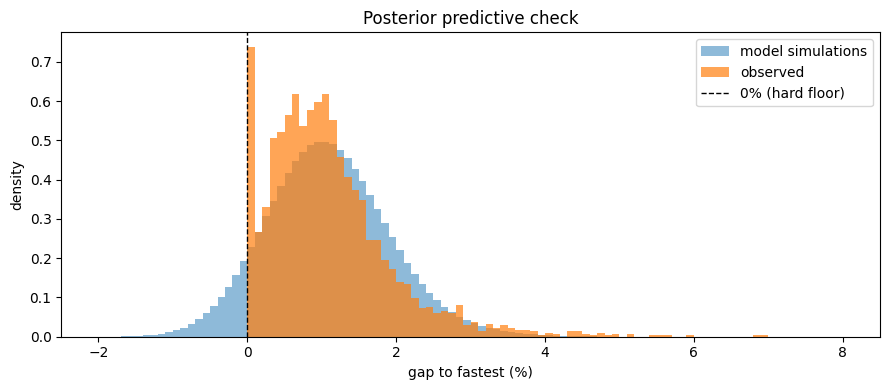

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(replicated, bins=100, range=(-2, 8), density=True, alpha=.5, label='model simulations')
ax.hist(observed, bins=100, range=(-2, 8), density=True, alpha=.7, label='observed')
ax.axvline(0, color='k', lw=1, ls='--', label='0% (hard floor)')
ax.set_xlabel('gap to fastest (%)')
ax.set_ylabel('density')
ax.legend()
ax.set_title('Posterior predictive check')
plt.tight_layout()
plt.show()

### Where the model fails

| | model | observed |
|---|---|---|
| negative values | **8.6%** | 0.0% |
| skew | **0.29** | 1.63 |
| max | 6.10% | 6.91% |
| median | 1.06% | 0.95% |

**The typical value is right and the shape is wrong.** The middle of the simulated distribution sits
at 1.06% against a real 0.95%. But 8.6% of simulated gaps are negative, meaning drivers lapping
faster than the fastest lap of their own session. And the simulation is nearly symmetric where the
real thing is lopsided, 0.29 against 1.63.

**One cause explains both.** A bell curve is symmetric, and the thing it is describing stops at zero
and trails away to the right. No amount of adjusting the priors changes that: the distribution is the
wrong shape.

### Two ways to fix the shape, and a trap between them

**Option one: a Student-t distribution on the same scale.** Fatter tails than a bell curve, so a few
extreme values do not drag the whole fit toward them. Still symmetric, so negative predictions stay
possible.

**Option two: model the square root of the gap.** Notebook 01 measured `sqrt(gap)` at a skew of
−0.10, near symmetric, which is what a bell curve wants. Squaring the predictions back cannot produce
a negative number.

**The trap: LOO cannot compare these two.** LOO scores predictions of whatever quantity the model
describes, and `sqrt(gap)` is a different quantity on a different scale. Comparing the scores needs a
correction I did not apply, so the two branches are judged separately: Student-t against the bell
curve by LOO, since both describe the same quantity, and the square-root version by squaring its
predictions back and checking those against reality.

In [14]:
from pytensor.compile.mode import Mode

# PyTensor's numba backend fails to compile the Student-t gradient on this stack;
# the C backend handles it
c_backend = Mode(linker='cvm', optimizer='fast_run')

model_t = bmb.Model(formula_v2, data=model_data, priors=priors_v2, family='t')
idata_t = model_t.fit(draws=2000, tune=1000, chains=4, random_seed=0, target_accept=0.95,
    idata_kwargs={'log_likelihood': True},
    compile_kwargs={'mode': c_backend})

print('divergences:', int(idata_t.sample_stats['diverging'].sum()))
print('worst R-hat:', az.summary(idata_t)['r_hat'].max())

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [nu, sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

/usr/local/lib/python3.12/dist-packages/pymc/sampling/mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 193 seconds.
There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


divergences: 5
worst R-hat: 1.0023869201202613


### Reading the comparison table

LOO scores how much probability a model gives to driver-sessions it was not shown, reported as
**elpd**. Higher is better, and the values mean something only against each other. `elpd_diff` is how
far a model sits behind the best one and `dse` is the margin of error on that gap: a difference
smaller than roughly twice its `dse` is not a difference.

In [15]:
comparison = az.compare({'normal': idata_v2, 'student_t': idata_t})
comparison

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
student_t,0,0.0,0.0,NaN,,,123.8,-2400.0,60.0,0.96
normal,1,-500.0,70.0,1.0,,,113.8,-2800.0,100.0,0.04


## Does the Student-t produce possible lap times?

LOO says which model predicts better, not whether either produces values that could occur. The
bell-curve model simulated 8.6% negative gaps, so the Student-t now faces the same test, measured
back on the original percentage scale.

In [16]:
model_t.predict(idata_t, kind='response', random_seed=0)
replicated_t = idata_t.posterior_predictive['gap_to_fastest'].values.flatten()

for label, values in [('normal', replicated), ('student_t', replicated_t)]:
    print(f'{label:10s} negative: {(values < 0).mean():5.1%}  '
          f'skew: {float(pd.Series(values).skew()):5.2f}  '
          f'max: {values.max():5.2f}%')
print(f'{"observed":10s} negative: {(observed < 0).mean():5.1%}  '
      f'skew: {pd.Series(observed).skew():5.2f}  max: {observed.max():5.2f}%')

normal     negative:  8.6%  skew:  0.29  max:  6.10%
student_t  negative:  7.3%  skew:  0.12  max: 191.52%
observed   negative:  0.0%  skew:  1.63  max:  6.91%


### The model with the best score is not an acceptable model

| | negative | skew | p99 | max |
|---|---|---|---|---|
| normal | 8.6% | 0.29 | 3.26% | 6.10% |
| student_t | 7.3% | **0.12** | 3.30% | 191.52% |
| observed | 0.0% | 1.63 | 3.95% | 6.91% |

**LOO prefers the Student-t decisively**, 500 elpd ahead, about seven times the margin of error and
96% of the model weight. **Its simulated data is not better shaped.** On two of the four columns it
edges the bell curve, putting 7.3% of predictions below zero against 8.6% and reaching 3.30% at the
ninety-ninth percentile against 3.26%, though both are still short of the observed 3.95%. On the two
that decide it, it is worse: its lopsidedness of 0.12 is further from the observed 1.63 than the bell
curve's 0.29, and it occasionally produces nonsense, that 191% maximum being one draw in 24 million
against an observed worst lap of 6.91%.

**Both results are correct.** LOO scores how much probability a model puts on the sessions that
actually happened, and fat tails give real outliers, a car four percent off the pace, much better
odds. Scoring the real data says nothing about whether the model's own simulations look like F1.

**The deeper problem is one they share.** Both are symmetric distributions describing something
floored at zero and trailing right. Neither can make that shape, which is why both leave 7 to 9% of
their predictions in territory that cannot exist. Picking the best-scoring model and stopping would
have shipped one that puts 7% of its predictions below zero.

## Modelling the square root of the gap

Squaring predictions back to percentages cannot produce a negative number, so the problem disappears
by arithmetic rather than tuning. Squaring a symmetric distribution also produces the right-skewed
shape real gaps have. The cost is readability: an effect on the square-root scale is no longer
directly a percentage of lap time, which is why notebook 03 converts everything back into seconds.

In [17]:
model_data['sqrt_gap'] = np.sqrt(model_data['gap_to_fastest'])

# sqrt(gap) sits near 1 with a spread around 0.4, so the priors scale down accordingly
priors_sqrt = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}

model_sqrt = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                       data=model_data, priors=priors_sqrt)

# no log_likelihood on this exploratory fit: comparing it against the untransformed
# models would need a Jacobian correction that I do not apply, and the group costs
# ~200MB. The shipped fit below does keep it, for its own Pareto-k check.
idata_sqrt = model_sqrt.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                            target_accept=0.95)

summary_sqrt = az.summary(idata_sqrt)
print('divergences:', int(idata_sqrt.sample_stats['diverging'].sum()))
print('worst R-hat:', summary_sqrt['r_hat'].max())
print('lowest ESS:', int(summary_sqrt['ess_bulk'].min()))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 58 seconds.
There were 11 divergences after tuning. Increase `target_accept` or reparameterize.


divergences: 11
worst R-hat: 1.0026797582137708
lowest ESS: 855


In [18]:
model_sqrt.predict(idata_sqrt, kind='response', random_seed=0)
# back to the percentage scale: squaring cannot produce a negative value
replicated_sqrt = (idata_sqrt.posterior_predictive['sqrt_gap'].values.flatten() ** 2)

rows = [('normal', replicated), ('student_t', replicated_t),
        ('sqrt', replicated_sqrt), ('observed', observed)]
for label, values in rows:
    print(f'{label:10s} negative: {(values < 0).mean():5.1%}  '
          f'median: {np.median(values):5.2f}%  '
          f'skew: {float(pd.Series(values).skew()):5.2f}  '
          f'p99: {np.percentile(values, 99):6.2f}%  '
          f'max: {values.max():8.2f}%')

normal     negative:  8.6%  median:  1.06%  skew:  0.29  p99:   3.26%  max:     6.10%
student_t  negative:  7.3%  median:  0.96%  skew:  0.12  p99:   3.30%  max:   191.52%
sqrt       negative:  0.0%  median:  0.92%  skew:  1.25  p99:   3.74%  max:     9.51%
observed   negative:  0.0%  median:  0.95%  skew:  1.63  p99:   3.95%  max:     6.91%


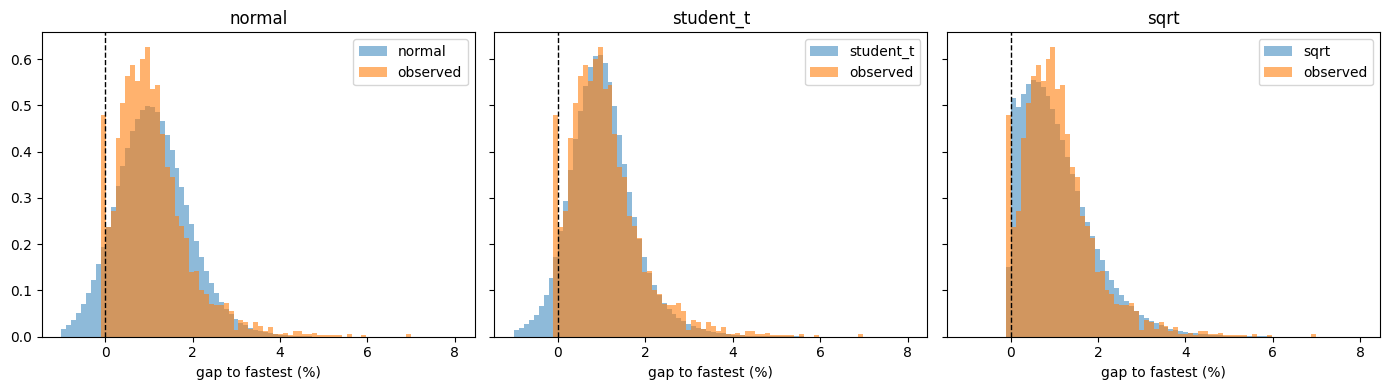

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (label, values) in zip(axes, rows[:3]):
    ax.hist(values, bins=80, range=(-1, 8), density=True, alpha=.5, label=label)
    ax.hist(observed, bins=80, range=(-1, 8), density=True, alpha=.6, label='observed')
    ax.axvline(0, color='k', lw=1, ls='--')
    ax.set_title(label)
    ax.set_xlabel('gap to fastest (%)')
    ax.legend()
plt.tight_layout()
plt.show()

### The square-root model is the realistic one

| | negative | median | skew | p99 | max |
|---|---|---|---|---|---|
| normal | 8.6% | 1.06% | 0.29 | 3.26% | 6.10% |
| student_t | 7.3% | 0.96% | 0.12 | 3.30% | **191.52%** |
| **sqrt** | **0.0%** | 0.92% | **1.25** | 3.74% | 9.51% |
| observed | 0.0% | 0.95% | 1.63 | 3.95% | 6.91% |

**No impossible values at all**, guaranteed by the arithmetic rather than achieved by tuning. The
typical simulated gap lands within 0.03 percentage points of the real one. The lopsidedness comes out
at 1.25 against an observed 1.63, where the other two managed 0.29 and 0.12.

**Its worst simulated lap is too slow**: a maximum of 9.5% against an observed 6.9%. That is a
different order of wrong from 191%. Neither maximum is visible in the histograms above, whose axes
stop at 8% so that the bulk of the distribution is readable; the table is where the tails are.

**It still understates the lopsidedness a little**, so it is the best of the three rather than a good
description in absolute terms.

**One diagnostic is worse than the others: 11 divergences**, against 0 and 5 for the other two. That
is 0.14% of samples, low but not zero, so it is worth trying to fix rather than ignoring. The standard
first move is raising `target_accept`, which makes the procedure take smaller steps.

In [20]:
def has_log_likelihood(idata):
    """`groups` is a method in some arviz versions and a property in others, and an
    empty group still satisfies hasattr, so check the contents."""
    group = getattr(idata, 'log_likelihood', None)
    return group is not None and len(group.data_vars) > 0


idata_sqrt_99 = model_sqrt.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                               target_accept=0.99,
                               idata_kwargs={'log_likelihood': True})

# This is the fit the rest of the project uses, so it should carry its own predictive
# diagnostics. Nothing below may raise: a failed extra must not discard the fit.
try:
    if not has_log_likelihood(idata_sqrt_99):
        model_sqrt.compute_log_likelihood(idata_sqrt_99)

    if has_log_likelihood(idata_sqrt_99):
        shipped_loo = az.loo(idata_sqrt_99, pointwise=True)
        # arviz 1.x names this `elpd` and supplies its own k threshold; older versions
        # call it `elpd_loo` and use a fixed 0.7
        elpd = getattr(shipped_loo, 'elpd', None)
        if elpd is None:
            elpd = shipped_loo.elpd_loo
        threshold = float(getattr(shipped_loo, 'good_k', 0.7))
        khat = np.asarray(shipped_loo.pareto_k)
        print(f'elpd_loo {float(elpd):+.1f}  (se {float(shipped_loo.se):.1f})')
        print(f'Pareto k above {threshold:.2f}: {int((khat > threshold).sum())} of '
              f'{khat.size} observations  (max {khat.max():.2f})')
        print('  a high k means LOO is unreliable for that point, not that the model is wrong')
    else:
        print('log-likelihood group unavailable, so no elpd or Pareto-k for the shipped fit')
except Exception as error:
    print('predictive diagnostics unavailable:', type(error).__name__, error)
print()

summary_99 = az.summary(idata_sqrt_99)
print('target_accept=0.99 ->')
print('  divergences:', int(idata_sqrt_99.sample_stats['diverging'].sum()))
print('  worst R-hat:', round(float(summary_99['r_hat'].max()), 4))
print('  lowest ESS :', int(summary_99['ess_bulk'].min()))
print()
print('group-level standard deviations (sqrt scale):')
print(summary_99.loc[['1|drv_sigma', '1|team_season_sigma', '1|season_sigma', 'sigma'],
                     ['mean', 'sd', 'ess_bulk', 'r_hat']].round(3))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

/usr/local/lib/python3.12/dist-packages/pymc/sampling/mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 107 seconds.


elpd_loo -664.3  (se 54.5)
Pareto k above 0.70: 0 of 3008 observations  (max 0.35)
  a high k means LOO is unreliable for that point, not that the model is wrong

target_accept=0.99 ->
  divergences: 0
  worst R-hat: 1.0063
  lowest ESS : 908

group-level standard deviations (sqrt scale):
                        mean       sd ess_bulk r_hat
1|drv_sigma           0.1375   0.0212     3545  1.00
1|team_season_sigma   0.2303   0.0216     2621  1.00
1|season_sigma         0.078     0.05      908  1.01
sigma                0.29631  0.00386    12152  1.00


### Divergences resolved

**`target_accept=0.99` removes them entirely**, at the cost of slower sampling. R-hat and effective
sample sizes stay healthy, so this is the model I carry forward.

| effect | sd (sqrt scale) |
|---|---|
| car (team-season) | **0.230** |
| driver | **0.138** |
| season | 0.078 |
| residual | 0.296 |

**Cars vary about 1.7 times as much as drivers**, 0.230 against 0.138.

**A note on that number, because notebook 03 reports it as 2.8 and both are right.** These are
standard deviations, a measure of typical spread. Notebook 03 works in variance instead, the standard
deviation squared, because variances of separate causes add together and can therefore be expressed
as shares of a total. Squaring 1.7 gives 2.8. Same fit, same finding, two scales.

That ordering, cars ahead of drivers, is what the untransformed model showed too, before its shape
problems disqualified it.

The season term is still the weakest number in the fit: R-hat 1.0063, which the table above rounds to
1.01, and the lowest effective sample size at 908. Eight seasons is little information for estimating
how much seasons differ.

## Saving the chosen model

Notebook 03 turns these numbers into a breakdown of where lap-time variation comes from, and into
driver rankings. Refitting takes minutes, so the fitted model is saved to disk instead.

In [21]:
# the log-likelihood group is roughly 200MB and has served its purpose above, so it
# does not travel with the artifact the downstream notebooks load
shipped = idata_sqrt_99.copy()
if has_log_likelihood(shipped):
    # item access, not attribute: InferenceData is DataTree-backed in this arviz
    del shipped['log_likelihood']
print('log-likelihood travels with the saved artifact:', has_log_likelihood(shipped))
shipped.to_netcdf('/kaggle/working/model_sqrt.nc')
model_data.to_csv('/kaggle/working/model_data.csv', index=False)
print('saved model_sqrt.nc and model_data.csv')
print('columns carried forward:', list(model_data.columns))

log-likelihood travels with the saved artifact: False
saved model_sqrt.nc and model_data.csv
columns carried forward: ['season', 'gp', 'team', 'drv', 'best_lap', 'n_valid_laps', 'gap_to_fastest', 'rain_fraction', 'within_107', 'team_season', 'sqrt_gap']


## What this notebook established

1. **Treating a car as "Mercedes 2019" rather than "Mercedes" reversed the answer.** Pooled across
   seasons, drivers looked more spread out (0.48) than cars (0.33), which is backwards for a
   sport where cars are separated by seconds and teammates by tenths. Giving each season its own car
   flipped it to 0.28 against 0.44 and **cut the driver effect by 43%**.

2. **The model LOO preferred was the one the reality check rejected.** The Student-t won by 500 elpd
   and 96% of the weight, while putting **7.3% of its predictions below zero**. A predictive score
   says nothing about whether a model's own simulations are possible.

3. **Cars vary about 1.7 times as much as drivers** (0.230 against 0.138), and what neither explains
   is larger than both at 0.296. Squared, those spreads become notebook 03's headline of 2.8 times.